# Logistic Regression

This notebook trains and evaluates Logistic Regression using the shared
dataset split, preprocessing pipeline, cross-validation approach and metrics.
Logistic Regression is used as a simple baseline because it is interpretable
and works well with scaled numeric features and one-hot encoded categories.

In [25]:
from pathlib import Path
import sys

ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "data/processed/hotel_booking_features.csv").is_file()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

from scripts.model_evaluation_utils import (
    RANDOM_STATE,
    OUTPUT_DIR,
    load_feature_dataset,
    split_feature_dataset,
    class_distribution,
    build_pipeline,
    cross_validation_summary,
    fit_and_evaluate,
    confusion_matrix_frame,
    save_results,
)

FIGURE_DIR = OUTPUT_DIR / "Figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load Shared Data Split

In [26]:
data = load_feature_dataset()
prepared = split_feature_dataset(data)

print(f"Training rows: {len(prepared.X_train):,}")
print(f"Test rows: {len(prepared.X_test):,}")

print("\nTraining class distribution")
display(class_distribution(prepared.y_train))

print("\nTest class distribution")
display(class_distribution(prepared.y_test))

Training rows: 95,364
Test rows: 23,841

Training class distribution


,class,count,percent
0,0,60008,62.9252
1,1,35356,37.0748



Test class distribution


,class,count,percent
0,0,15002,62.9252
1,1,8839,37.0748


## 2. Baseline Model

In [27]:
logistic_model = LogisticRegression(
    max_iter=1000,
    solver="lbfgs",
    random_state=RANDOM_STATE,
)
logistic_pipeline = build_pipeline(logistic_model, prepared.X_train)
logistic_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",1.0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be exclude

## 3. Cross-Validation

In [28]:
logistic_cv = cross_validation_summary(
    "Logistic Regression",
    "Baseline",
    logistic_pipeline,
    prepared.X_train,
    prepared.y_train,
)
display(logistic_cv.round(4))

,model,version,metric,train_mean,train_std,cv_mean,cv_std
0,Logistic Regression,Baseline,accuracy,0.8222,0.0008,0.8209,0.0017
1,Logistic Regression,Baseline,precision,0.8073,0.0012,0.8058,0.0042
2,Logistic Regression,Baseline,recall,0.6836,0.0014,0.6814,0.0084
3,Logistic Regression,Baseline,f1,0.7403,0.0012,0.7383,0.0039
4,Logistic Regression,Baseline,roc_auc,0.9048,0.0004,0.9039,0.0009
5,Logistic Regression,Baseline,pr_auc,0.8669,0.0004,0.8657,0.0010


**Interpretation:** Logistic Regression shows how well a simple linear model
can separate cancelled and non-cancelled bookings after the shared
preprocessing step. The cross-validation metrics are used to judge expected
generalization before looking at the final test set. A small gap between
training and validation scores indicates limited overfitting.

## 4. Final Test Evaluation

In [29]:
logistic_pipeline, logistic_test = fit_and_evaluate(
    "Logistic Regression",
    "Baseline",
    logistic_pipeline,
    prepared,
)

logistic_test_results = pd.DataFrame([logistic_test])
display(logistic_test_results.round(4))

,model,version,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
0,Logistic Regression,Baseline,0.8243,0.8131,0.6832,0.7425,0.9051,0.8684,1.7032


**Test-set interpretation:** The final test metrics should be compared with
the cross-validation results. If the values are close, the model is behaving
consistently on unseen data. For this dataset, Logistic Regression is useful
as a stable and interpretable baseline, but its recall should be checked
carefully because low recall means more actual cancellations are missed.

## 5. Confusion Matrix

In [30]:
logistic_predictions = logistic_pipeline.predict(prepared.X_test)
logistic_confusion = confusion_matrix_frame(prepared.y_test, logistic_predictions)
display(logistic_confusion)

,Predicted 0,Predicted 1
Actual 0,13614,1388
Actual 1,2800,6039


## 6. ROC and Precision-Recall Curves

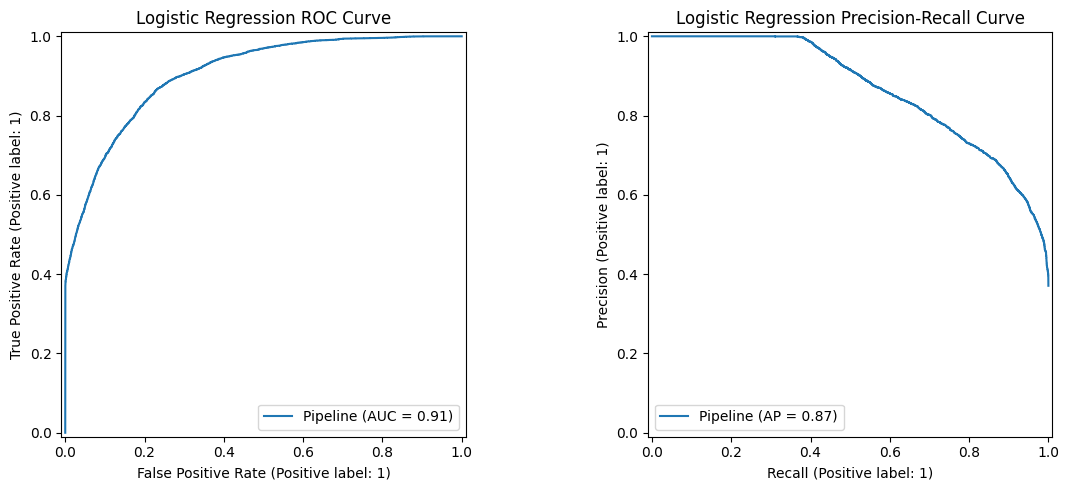

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_estimator(logistic_pipeline, prepared.X_test, prepared.y_test, ax=axes[0])
PrecisionRecallDisplay.from_estimator(logistic_pipeline, prepared.X_test, prepared.y_test, ax=axes[1])
axes[0].set_title("Logistic Regression ROC Curve")
axes[1].set_title("Logistic Regression Precision-Recall Curve")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "logistic_regression_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Save Results

In [32]:
test_path = save_results(logistic_test_results, "logistic_regression_test_results.csv")
cv_path = save_results(logistic_cv, "logistic_regression_cv_results.csv")

print(f"Saved final test results to: {test_path.relative_to(ROOT)}")
print(f"Saved CV results to: {cv_path.relative_to(ROOT)}")

Saved final test results to: 06_Model_Evaluation\logistic_regression_test_results.csv
Saved CV results to: 06_Model_Evaluation\logistic_regression_cv_results.csv


## 8. Interpretation Notes

Logistic Regression should remain in the final comparison as the linear
baseline. It is easy to explain and usually less prone to overfitting than a
fully grown tree. If its ROC-AUC is strong but recall/F1 are lower than tree
models, the discussion should explain that it ranks cancellation risk well
overall but may miss more cancelled bookings at the default 0.50 threshold.